# Do one-year matrices describe a cohort? Markov tests, momentum and the ECB stability tests

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 02 and 03 of this topic (the pooled matrix and the generators)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- test whether a one-year matrix is the same every year (time homogeneity) and whether each year agrees with the pooled matrix, and read a statistic that is eleven times its degrees of freedom;
- compute the ECB's matrix weighted bandwidth and migration z-tests on each cohort, and the mobility indices beside the speculative-grade default rate;
- run the order test and the momentum test on rating paths, and see on a dataset with planted momentum that the homogeneity test does not detect it;
- read the committed power study: how often each test rejects as the momentum or the stress grows;
- compare the five-year default frequency a cohort lived with what the one-year matrices project, and say which three different things the numbers count.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import mobility
from riskvalidation.validation import rating_system, transitions as tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Five committed files of case C04, from ESMA's CEREP publication (licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: the S&P annual and semester count tables, the pooled matrix, and what the case computed from them: `outputs.homogeneity`, `outputs.ecb`, `outputs.mobility`, `outputs.lifetime`.
- `data/derived/C04/models-transitions.json`: the generator fitted to S&P's counts, the known truth of the simulated datasets.
- `data/derived/C04/momentum.json` and `data/derived/C04/cycle.json`: two committed simulation studies of 200 seeded datasets per rung, one with a self-exciting downgrade intensity (momentum) of growing strength, one with the downgrade rates multiplied by a factor in the third year (a stressed regime).

CEREP has counts, never individual paths, so the real data can run the tests that need only count tables (homogeneity, the ECB tests) and cannot run the order test (it needs the state at three consecutive dates of each obligor) or the momentum test (it needs the path). Those two run on simulated paths, drawn here from the committed generator.

The next cell loads the files and prints the engine version that baked them.

In [2]:
# Load the artifacts (the notebook sits three folders below the repository root) and build the square count tables
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, models, momentum, cycle = load("sp.json"), load("models-transitions.json"), load("momentum.json"), load("cycle.json")
out = sp["outputs"]
grades, states = out["grades"], out["states"]
P = np.array(out["pooled"]["matrix"], dtype=float)
annual = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in out["cohorts"]]
semesters = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in out["semesters"]]

for label, doc in (("sp", sp), ("models-transitions", models), ("momentum", momentum), ("cycle", cycle)):
    print(f"{label:20s} baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("annual tables:", len(annual), "| semester tables:", len(semesters))

sp                   baked by riskvalidation 0.4.3 | installed 0.9.0
models-transitions   baked by riskvalidation 0.4.3 | installed 0.9.0
momentum             baked by riskvalidation 0.4.3 | installed 0.9.0
cycle                baked by riskvalidation 0.4.3 | installed 0.9.0
annual tables: 26 | semester tables: 32


## Method

### Step 1: is the matrix the same every year?

Anderson and Goodman (1957) test time homogeneity: whether the transition probabilities $p_{ij}(t)$ are the same in every period against the pooled $\hat p_{ij}$. Their chi-square form (equation 3.8) sums, over the starting states $i$ (the absorbing default row carries no information), the periods $t$ and the end states $j$,

$$\chi^2 = \sum_i \sum_{t, j} n_i(t-1)\,\frac{\bigl(\hat p_{ij}(t) - \hat p_{ij}\bigr)^2}{\hat p_{ij}}$$

with $n_i(t-1)$ the ratings that started period $t$ in $i$. Under the null it is asymptotically chi-square with $(T-1)(m-1)$ degrees of freedom per row, where the empty cells and periods are removed (the engine's convention). The likelihood-ratio form (3.5) is in the result too. The engine's `rating_time_homogeneity` takes the stack of count tables. The cell calls it on the 26 annual tables and on the 32 semester tables, prints the per-grade contributions and compares with the committed numbers. A statistic is read against its degrees of freedom: under the null the two are of the same size.

In [3]:
# Time homogeneity across the 26 annual and the 32 semester tables, per-grade contributions, committed comparison
hom_annual = tests.rating_time_homogeneity(annual, model_id="STPGB", segment="annual")
hom_semesters = tests.rating_time_homogeneity(semesters, model_id="STPGB", segment="semesters")
committed = out["homogeneity"]

print("baked by riskvalidation", sp["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
for label, r, c in (("annual", hom_annual, committed["annual"]), ("semesters", hom_semesters, committed["semesters"])):
    print(f"{label:11s} chi2 = {r.statistic:10.2f} | degrees of freedom = {r.extras['dof']} | chi2 / dof = {r.statistic / r.extras['dof']:.2f} | p = {r.p_value:.3g} | light: {r.light.value} | committed: {c['statistic']:.2f} on {c['dof']}")
print(f"{'grade':8s}{'chi2':>10s}{'dof':>8s}{'chi2 / dof':>12s}")
rows = hom_annual.extras["rows"]
for row in rows:
    print(f"{grades[row['row']]:8s}{row['chi2']:10.2f}{row['dof']:8d}{row['chi2'] / row['dof']:12.2f}")
print("the grade contributions add up to the statistic:", bool(np.isclose(sum(r['chi2'] for r in rows), hom_annual.statistic)))

baked by riskvalidation 0.4.3 | installed 0.9.0
annual      chi2 =   12028.16 | degrees of freedom = 1075 | chi2 / dof = 11.19 | p = 0 | light: red | committed: 12028.16 on 1075
semesters   chi2 =   14248.61 | degrees of freedom = 899 | chi2 / dof = 15.85 | p = 0 | light: red | committed: 14248.61 on 899
grade         chi2     dof  chi2 / dof
AAA         330.13     100        3.30
AA         5763.16     175       32.93
A          1562.54     175        8.93
BBB        1370.75     175        7.83
BB          971.37     175        5.55
B          1638.98     150       10.93
CCC-C       391.23     125        3.13
the grade contributions add up to the statistic: True


The statistic is far above its degrees of freedom, and the p-value is below the smallest number the double-precision floating point holds (the engine reports 0). With about 170,000 rating-years the test has the power to see any difference between years, and the matrix does change from year to year. What the test does **not** say is which departure from the Markov model produced the rejection (a change of regime over time, momentum, something else), which Step 5 returns to.

### Step 2: each year against the pooled matrix

A second reading asks, for each year separately, whether its counts are compatible with the pooled matrix as a specified reference. The engine's `rating_matrix_reference` uses by default the likelihood ratio $2\sum n_{ij} \log(\hat p_{ij} / p^0_{ij})$ (the likelihood-ratio analogue of Anderson and Goodman's equation 3.1, chosen because it held its size where the printed form did not) and also reports any move the pooled matrix calls impossible (a count where the reference has zero). The next cell runs it on the 26 cohorts and counts the rejections at 5% and 1%.

In [4]:
# Each annual cohort against the pooled matrix, with the committed statistics and the impossible moves
refs = [tests.rating_matrix_reference(t, P, model_id="STPGB", segment=c["label"]) for t, c in zip(annual, out["cohorts"])]
stat = np.array([r.statistic for r in refs])
dof = np.array([r.extras["dof"] for r in refs])
pvals = np.array([r.p_value for r in refs])
committed_ref = committed["reference"]
print("cohorts rejected at 5%:", int((pvals < 0.05).sum()), "of", len(refs), "| at 1%:", int((pvals < 0.01).sum()))
print("chi2 / dof: smallest", round(float((stat / dof).min()), 2), "in", out["cohorts"][int((stat / dof).argmin())]["label"], "| largest", round(float((stat / dof).max()), 2), "in", out["cohorts"][int((stat / dof).argmax())]["label"])
print("cohorts with an impossible move:", sum(1 for r in refs if r.extras["impossible_moves"]))
print("statistics equal the committed ones:", bool(np.allclose(stat, [c["statistic"] for c in committed_ref], atol=1e-6)))
print(f"{'cohort':8s}{'LR':>10s}{'dof':>6s}{'p':>12s}")
for r, c in list(zip(refs, out["cohorts"]))[:3]:
    print(f"{c['label']:8s}{r.statistic:10.2f}{r.extras['dof']:6d}{r.p_value:12.3g}")

cohorts rejected at 5%: 26 of 26 | at 1%: 26
chi2 / dof: smallest 2.27 in 2012 | largest 55.27 in 2021
cohorts with an impossible move: 0
statistics equal the committed ones: True
cohort          LR   dof           p
2000        316.53    43    2.34e-43
2001        413.39    43       5e-62
2002        723.70    43   1.91e-124


Every one of the 26 years rejects the pooled matrix, in the smallest statistic as in the largest. That is what a matrix pooled over regimes does to a single year.

### Step 3: the ECB's stability tests on each cohort

The ECB's reporting template (ECB, 2019, section 2.5.5) asks two things of a rating system's migration matrix. The **matrix weighted bandwidth** (MWB, section 2.5.5.1) measures how far ratings migrate: for downgrades (upper) and upgrades (lower), the average distance of the migrations weighted by the obligors, relative to the largest possible distance from each grade; 0 when nobody migrates, 1 at the extreme. It is descriptive, so the default policy gives no light. The **migration z-tests** (section 2.5.5.2) check that, in each row, the frequency of moving does not increase when moving further from the diagonal: one z-test per off-diagonal cell against its neighbour closer to the diagonal. The engine adds a Holm adjustment across the cells and reports the smallest adjusted p-value. Both apply to the block of transitions between the performing grades. The next cell runs them on each cohort and compares with the committed rows.

In [5]:
# MWB and migration z-tests on the 7 x 7 performing block of every cohort, compared with the committed rows
blocks = [np.array(c["counts"], dtype=float)[:, :7] for c in out["cohorts"]]
mwb = [rating_system.rating_mwb(b, model_id="STPGB", segment=c["label"]) for b, c in zip(blocks, out["cohorts"])]
ztest = [rating_system.rating_migration_ztests(b, model_id="STPGB", segment=c["label"]) for b, c in zip(blocks, out["cohorts"])]
committed_ecb = out["ecb"]

up = np.array([r.extras["mwb_upper"] for r in mwb])
low = np.array([r.extras["mwb_lower"] for r in mwb])
zp = np.array([r.p_value for r in ztest])
same = all(np.isclose(a, b["mwb_upper"], atol=1e-8) and np.isclose(c, b["mwb_lower"], atol=1e-8) and np.isclose(d, b["ztests_p"], atol=1e-8)
           for a, c, d, b in zip(up, low, zp, committed_ecb))
print("equal to the committed rows:", same, "| light of MWB:", mwb[0].light.value)
print(f"{'cohort':8s}{'MWB up':>12s}{'MWB low':>12s}{'z-tests p (Holm)':>26s}{'cells with raw p < 0.05':>34s}")
for k in (0, int(up.argmax()), len(up) - 1):
    print(f"{out['cohorts'][k]['label']:8s}{up[k]:12.4f}{low[k]:12.4f}{zp[k]:26.4f}{ztest[k].statistic:34.0f}")
print("cohorts where the smallest Holm p is below 0.05:", int((zp < 0.05).sum()), "of", len(zp))

equal to the committed rows: True | light of MWB: not_evaluated
cohort        MWB up     MWB low          z-tests p (Holm)           cells with raw p < 0.05
2000          0.2678      0.2878                    0.9946                                 1
2001          0.2732      0.2699                    0.0099                                 2
2025          0.2269      0.2310                    1.0000                                 0
cohorts where the smallest Holm p is below 0.05: 2 of 26


### Step 4: how much does the matrix move, and when

The mobility indices summarise a whole matrix in one number. The engine's `svd_mobility` returns the mean singular value of $P - I$ (the index of Jafry and Schuermann, 2004) and `trace_mobility` the trace index $(n - \mathrm{tr} P)/(n-1)$. Both are 0 for an identity matrix. The artifact commits them for each cohort's own matrix beside the cohort's speculative-grade default rate. The next cell recomputes the two on the pooled matrix, reads the committed series and draws them against the default rate by year.

pooled matrix: M_SVD = 0.1353 | trace index = 0.1372
most mobile year: 2002 0.2189 | least mobile: 2023 0.0658
years with both series: 26 | correlation of M_SVD with the speculative-grade default rate: 0.269


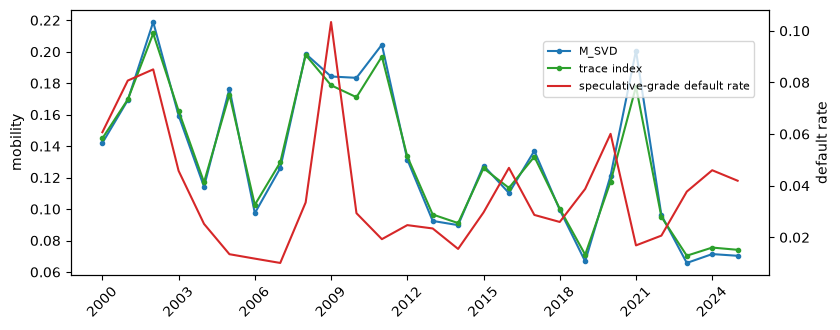

In [6]:
# Mobility of the pooled matrix, the committed yearly series, and their link with the speculative-grade default rate
mob = out["mobility"]
svd = np.array([np.nan if v is None else v for v in mob["svd"]])
trace = np.array([np.nan if v is None else v for v in mob["trace"]])
spec = np.array([np.nan if v is None else v for v in mob["spec_default_rate"]])
ok = np.isfinite(svd) & np.isfinite(spec)
labels = mob["labels"]

print("pooled matrix: M_SVD =", round(mobility.svd_mobility(P), 4), "| trace index =", round(mobility.trace_mobility(P), 4))
print("most mobile year:", labels[int(np.nanargmax(svd))], round(float(np.nanmax(svd)), 4), "| least mobile:", labels[int(np.nanargmin(svd))], round(float(np.nanmin(svd)), 4))
print("years with both series:", int(ok.sum()), "| correlation of M_SVD with the speculative-grade default rate:", round(float(np.corrcoef(svd[ok], spec[ok])[0, 1]), 3))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(labels, svd, color="tab:blue", marker="o", markersize=3, label="M_SVD")
ax.plot(labels, trace, color="tab:green", marker="o", markersize=3, label="trace index")
ax.set_ylabel("mobility")
ax2 = ax.twinx()
ax2.plot(labels, spec, color="tab:red", label="speculative-grade default rate")
ax2.set_ylabel("default rate")
ax.set_xticks(range(0, len(labels), 3))
ax.set_xticklabels(labels[::3], rotation=45)
fig.legend(loc="upper right", fontsize=8, bbox_to_anchor=(0.9, 0.88))
fig.tight_layout()
plt.show()

### Step 5: order and momentum, on paths whose truth is known

Two more departures from the Markov model matter in practice. The **order** test (Anderson and Goodman, equation 3.12) asks whether the next state depends on the previous one as well as on the current one. The engine's default groups the previous and next states by direction (from a better grade, the same, a worse one; to a better, the same, a worse one), the grouping that momentum acts on. The **momentum** test (dos Reis, Pfeuffer and Smith, 2020) fits the hazard of leaving a grade as $\lambda(t) = q_i(t)\, e^{cZ}$ with $Z = 1$ for an obligor downgraded into its current grade, and tests $c = 0$ by a likelihood ratio.

Neither can run on CEREP's counts. The next cell draws two datasets from the committed generator, with a seed and the same number of obligors: one Markov, one where every downgrade raises the intensity of further downgrades (`RatingPaths` momentum with strength 0.125 and decay 1 per year, the strength at which the committed study recovers the hazard coefficient that dos Reis et al. estimate on Moody's data). It runs the three tests on each. The engine reports the fitted momentum coefficient $c$, which is 0 for a Markov chain.

In [7]:
# Draw a Markov and a momentum dataset from the committed generator and run the three tests on each
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
n_obligors = tuple(models["fit"]["generator"]["obligors"])
snapshots = tuple(float(t) for t in range(6))
planted = {"markov": {}, "momentum": dict(momentum=((0.125, 1.0), (0.125, 1.0)), investment_grades=4)}

print(f"{'dataset':12s}{'homogeneity p':>24s}{'order p':>16s}{'momentum p':>18s}{'fitted c':>14s}")
verdicts = {}
for label, defect in planted.items():
    data = RatingPaths(q_true, n_obligors, horizon=5.0, snapshots=snapshots, **defect).draw(np.random.default_rng(20261021))
    hom = tests.rating_time_homogeneity([s["counts"] for s in data["steps"]])
    order = tests.rating_markov_order(data["triplets"])
    mom = tests.rating_momentum(data["segments"])
    verdicts[label] = (hom.p_value, order.p_value, mom.p_value)
    name = {"markov": "Markov", "momentum": "momentum"}[label]
    print(f"{name:12s}{hom.p_value:24.3g}{order.p_value:16.3g}{mom.p_value:18.3g}{mom.extras['coefficient']:14.3f}")

dataset                homogeneity p         order p        momentum p      fitted c
Markov                         0.528            0.16             0.352         0.047
momentum                        0.43        1.96e-13          2.98e-13         0.347


On the Markov dataset no test rejects. On the dataset with momentum the order and the momentum tests reject with a p-value near $10^{-13}$, and the homogeneity test does not reject at all: the matrix is the same every year, the chain simply is not Markov. A rejection of homogeneity therefore cannot be read as momentum, and an absence of rejection does not clear a chain of it. One draw is one sample; the committed study below counts how often each test rejects over 200.

In [8]:
# Read the committed power studies: rejection rates at 5% along the momentum ladder and along the stress ladder
def rate(study, test_id, rung):
    row = next(s for s in study["outputs"]["simulations"] if s["test_id"] == test_id and s["rung"] == rung)
    return row["rates"]["p<0.05"]["rate"]

alphas = momentum["outputs"]["ladder"]["values"]
print(momentum["outputs"]["simulations"][0]["n_rep"], "datasets per row")
print(f"{'momentum strength':24s}" + "".join(f"{a:>8.3f}" for a in alphas))
for test_id, label in (("rating.time_homogeneity", "homogeneity"), ("rating.markov_order", "order"), ("rating.momentum", "momentum")):
    print(f"{label:24s}" + "".join(f"{rate(momentum, test_id, a):8.3f}" for a in alphas))
factors = cycle["outputs"]["ladder"]["values"]
print(f"{'third-year stress k':24s}" + "".join(f"{k:>8.2f}" for k in factors))
for test_id, label in (("rating.time_homogeneity", "homogeneity"), ("rating.matrix_reference", "year vs pooled")):
    print(f"{label:24s}" + "".join(f"{rate(cycle, test_id, k):8.3f}" for k in factors))

200 datasets per row
momentum strength          0.000   0.025   0.050   0.125   0.250
homogeneity                0.035   0.030   0.045   0.085   0.115
order                      0.085   0.110   0.335   1.000   1.000
momentum                   0.050   0.350   0.865   1.000   1.000
third-year stress k         1.00    1.25    1.50    2.00    3.00
homogeneity                0.040   0.295   0.980   1.000   1.000
year vs pooled             0.000   0.275   0.995   1.000   1.000


### Step 6: the chain against the cohort that lived it

The point of a matrix is a projection. The artifact holds, for five windows of five years, the fixed cohort of the window's first year followed to its end (`outputs.lifetime`) beside what the window's one-year matrices project. Three numbers need to be told apart. **Lived, defaulted (`cumulative_d2`)**: every rated defaulter, from the default page. **Lived, in default at the end (`default_end`)**: ratings still in a default category on the transition page at the window's end, which misses defaults withdrawn or re-rated within the window. **Chained**: the window's five annual matrices multiplied, withdrawals as an absorbing state, so a rating that defaulted counts; by definition it lies between the other two. The pooled matrix to the fifth power and the EM generator project the same horizon without the window's own matrices. The cell prints the last window for grades B and CCC-C and the share withdrawn.

In [9]:
# The last five-year window: lived and projected five-year default shares for B and CCC-C, and the share withdrawn
window = out["lifetime"][-1]
print("window:", window["label"], "| cohort sizes B and CCC-C:", window["size"][5], window["size"][6])
rows = (
    ("lived: every defaulter (cumulative_d2)", window["observed"]["cumulative_d2"]),
    ("lived: in default at the end (default_end)", window["observed"]["default_end"]),
    ("chained annual matrices, withdrawals a state", window["projected"]["chain_state"]),
    ("chained, withdrawals removed", window["projected"]["chain_exclude"]),
    ("pooled matrix to the fifth power", window["projected"]["pooled_power"]),
    ("EM generator, five years", window["projected"]["em"]),
    ("share withdrawn by the end", window["observed"]["withdrawn_end"]),
)
print(f"{'':74s}{'B':>10s}{'CCC-C':>10s}")
for label, values in rows:
    print(f"{label:74s}{values[5]:10.4f}{values[6]:10.4f}")
print("chained lies between the two lived numbers (B and CCC-C):",
      [bool(window["observed"]["default_end"][g] <= window["projected"]["chain_state"][g] <= window["observed"]["cumulative_d2"][g]) for g in (5, 6)])

window: 2020-2024 | cohort sizes B and CCC-C: 1846 238
                                                                                   B     CCC-C
lived: every defaulter (cumulative_d2)                                        0.1126    0.6144
lived: in default at the end (default_end)                                    0.0060    0.0000
chained annual matrices, withdrawals a state                                  0.0259    0.0910
chained, withdrawals removed                                                  0.0440    0.2047
pooled matrix to the fifth power                                              0.0821    0.2530
EM generator, five years                                                      0.0821    0.2527
share withdrawn by the end                                                    0.5531    0.8109
chained lies between the two lived numbers (B and CCC-C): [True, True]


## Results

- **The matrix is not the same every year.** The annual chi-square is 12,028.16 on 1,075 degrees of freedom (11.2 times its degrees of freedom; p underflows to 0, red) and the semester one 14,248.61 on 899 (15.9 times). AA contributes the most per degree of freedom (32.9) and CCC-C the least (3.1). Each of the 26 years rejects the pooled matrix as well (the statistic over its degrees of freedom runs from 2.27 in 2012 to 55.27 in 2021), with no impossible move. All equal the committed values.
- **The ECB's stability tests.** The matrix weighted bandwidth of 2000 is 0.268 for downgrades and 0.288 for upgrades; it is descriptive and carries no light. The migration z-tests, Holm-adjusted across cells, flag 2 of the 26 cohorts at 5% (2001 has p = 0.0099). All equal the committed rows.
- **Mobility.** The pooled matrix has M_SVD 0.135 and trace index 0.137. The most mobile year is 2002 (0.219) and the least 2023 (0.066). Over the 26 years M_SVD correlates 0.27 with the speculative-grade default rate: movement and defaults are related but far from the same thing.
- **Homogeneity cannot see momentum.** On the seeded Markov dataset no test rejects (p = 0.53, 0.16 and 0.35; fitted c = 0.05). On the seeded dataset with momentum the order test (p = 2e-13) and the momentum test (p = 3e-13, fitted c = 0.35) reject and the homogeneity test does not (p = 0.43). In the committed 200-dataset study, at momentum strength 0.125 the homogeneity test rejects 8.5% of the datasets at 5% (3.5% with no momentum), the order test and the momentum test 100%. A stressed third year, instead, is seen by homogeneity: 29.5% at k = 1.25, 98% at k = 1.5.
- **Chained against lived.** In the 2020 to 2024 window, 61.4% of the CCC-C cohort defaulted (every rated defaulter) while none was still in default at the end and 81.1% had been withdrawn; the chained annual matrices give 9.1% and the pooled matrix to the fifth power 25.3%. For B the numbers are 11.3% lived, 2.6% chained, 8.2% pooled power, 55.3% withdrawn. The chained value lies between the two lived readings, as its definition says; with 81.1% of the CCC-C cohort gone through withdrawal, the comparison cannot separate a failure of the Markov chain from the way withdrawals are counted.

What this notebook does not show: how to carry a PD curve to a new year (notebook 05), or what a PD costs in capital (notebook 07).

## Summary

- Time homogeneity, the year-against-pooled test, the order test and the momentum test ask different questions; a rejection of one does not name the departure, and a pass does not clear the chain of the others.
- The ECB's matrix weighted bandwidth is descriptive and its migration z-tests, adjusted across cells, flag few cohorts here; the mobility indices move with the cycle but are not the default rate.
- Rating counts alone support homogeneity and the ECB tests; order and momentum need paths, so they run on simulated paths of known truth.
- A projection is compared with what a cohort lived only after saying which of the three default numbers each counts.

**What to try next.** Change the momentum strength in the draw of Step 5 to 0.05 and rerun it several times with other seeds; then read notebook 05.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equations 3.1, 3.5, 3.8 and 3.12. https://doi.org/10.1214/aoms/1177707039
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, section 2.5.5 (matrix weighted bandwidth and migration z-tests). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Jafry, Y. and Schuermann, T. (2004), Measurement, estimation and comparison of credit migration matrices, Journal of Banking and Finance 28(11), for the mobility indices.
- dos Reis, G., Pfeuffer, M. and Smith, G. (2020), Capturing model risk and rating momentum in the estimation of probabilities of default and credit rating migrations, Quantitative Finance, arXiv 1809.09889.
- Holm, S. (1979), A simple sequentially rejective multiple test procedure, Scandinavian Journal of Statistics 6(2), for the adjustment across cells.